In [ ]:
from evaluation_utils import *
RESULTS_PATH = os.path.join(RESULTS_DIR, "hier_lorenz_sac_2")

In [ ]:
# Use a plain string (no nested f-string/quotes). For an absolute path use four slashes.
storage_url = "sqlite:///" + RESULTS_PATH + "/optuna_study.db"
param_importances, study, idx_best_trial, idx_best_intermediate_trial = optuna_overview(
    storage_url, plot=True, remove_trials=False)

best_trial = get_trial_by_number(study.trials, idx_best_trial)
print("Parameters:")
for param in param_importances.keys():
    print(
        f"  {param} imp: {param_importances[param]:.4f}, best: {best_trial.params.get(param)}")
#remove_pruned_trial_folders(study, RESULTS_PATH)

## Evaluation

In [4]:
from src.models.mtf_sac_model import MTF_SAC_Model
from src.main import init_dataset
from src.environments.lorenz63 import integrate_controlled_lorenz

GOAL_STATE = tc.tensor([0.5, 0.5, -0.5])
T_DYNAMICS = 200
T_CONTROL = 50
CONTROL_STATUS = np.concatenate(([0]*T_DYNAMICS, [1]*T_CONTROL)*3)
TIME_SERIES_PER_MEASUREMENT = 4
RUN = "001"
DEVICE = tc.device("cpu")
DATASET = init_dataset(json.load(open(RESULTS_DIR + '/hier_lorenz_3/params_ldim=26_relu=12_feature_dim=4_dsr_lr=0p01_lr_gamma=1p00_gtf=0p06_gtf_gamma=1p00_aent=0p89_adsr=114p61_ac=4p55_ar=3p83_asc=0p32_alpha_mar=1p90_mar=0/001/config.json')), DEVICE)
MEASUREMENT_INDEX_TO_TS_INDEX = {DATASET.evaluator_test_samples[i].measurement_index: DATASET.evaluator_test_samples[i].cumulative_timeseries_index for i in range(len(DATASET.evaluator_test_samples)-1, -1, -1)}

Sequence length set to 30.


In [ ]:
trial_folder_name = "params_q_hid1=29_policy_hid1=20_env_steps=14_polyak_tau=0p01_noise=0p00_q_lr=0p00_policy_lr=0p00_q_lr_gamma=1p00_policy_lr_gamma=1p00_aq=275p00_apolicy=34p46_areg_q=63p75_areg_policy=0p10_areg_temp=1p89_q_hid2=25_policy_hid2=18"
runs = sorted(os.listdir(os.path.join(RESULTS_PATH, trial_folder_name)))
rewards_true = np.zeros((len(runs), 64, 5))
rewards_model = np.zeros((len(runs), 64, 5))

tc.manual_seed(1)
for k, run in enumerate(runs):
    run_path = os.path.join(RESULTS_PATH, trial_folder_name, run)

    parameters = json.load(open(f"{run_path}/config.json"))
    mtf_parameters = json.load(open(f"{parameters["world_model"]["path"]}/config.json"))
    model = MTF_SAC_Model(DATASET, model_path=run_path, device=DEVICE)
    
    reward_true = []
    reward_model = []
    
    for measurement_index in range(64):
        for i in range(5):
            x0 = DATASET.evaluator_test_samples[measurement_index*TIME_SERIES_PER_MEASUREMENT].input[tc.randint(0, 200, (1,))][0]
            observed_trajectory, _, actions = integrate_controlled_lorenz(model, x0, measurement_index, MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index], T=500, apply_actions=True, expected=True)
            rewards_true[k, measurement_index, i] = model.reward_function(observed_trajectory[:, 1:], actions, measurement_index).detach().squeeze()[15:].mean()
            
            cumulative_timeseries_index = MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index]
            (observed_trajectory,
            _,
            actions,
            _,
            _,
            _,
            _,
            _) = model.generate_free_trajectory(
                    x0.unsqueeze(0),
                    cumulative_timeseries_index,
                    measurement_index,
                    apply_actions=True,
                    T=500, 
                    expected =True,
            )
            rewards_model[k, measurement_index, i] = model.reward_function(observed_trajectory[:, 1:], actions, measurement_index).detach().squeeze()[15:].mean()

RESULTS_PATH = os.path.join(RESULTS_DIR, "hier_lorenz_sac_2_separate")
trial_folder_name = "params_q_hid1=35_policy_hid1=25_env_steps=19_polyak_tau=0p00_noise=0p03_q_lr=0p00_policy_lr=0p00_q_lr_gamma=1p00_policy_lr_gamma=1p00_aq=521p85_apolicy=39p61_areg_q=18p80_areg_policy=49p57_areg_temp=0p00_q_hid2=28_policy_hid2=25"
runs = sorted(os.listdir(os.path.join(RESULTS_PATH, trial_folder_name)))
rewards_true_separate = np.zeros((len(runs), 64, 5))
rewards_model_separate = np.zeros((len(runs), 64, 5))
    
tc.manual_seed(1)
for k, run in enumerate(runs):
    run_path = os.path.join(RESULTS_PATH, trial_folder_name, run)
    parameters = json.load(open(f"{run_path}/config.json"))
    mtf_parameters = json.load(open(f"{parameters["world_model"]["path"]}/config.json"))
    model = MTF_SAC_Model(DATASET, model_path=run_path, device=DEVICE)
    
    for measurement_index in range(64):
        for i in range(5):
            x0 = DATASET.evaluator_test_samples[measurement_index*TIME_SERIES_PER_MEASUREMENT].input[tc.randint(0, 200, (1,))][0]
            observed_trajectory, _, actions = integrate_controlled_lorenz(model, x0, measurement_index, MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index], T=500, apply_actions=True, expected=True)
            rewards_true_separate[k, measurement_index, i] = model.reward_function(observed_trajectory[:, 1:], actions, measurement_index).detach().squeeze()[15:].mean()
            
            cumulative_timeseries_index = MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index]
            (observed_trajectory,
            _,
            actions,
            _,
            _,
            _,
            _,
            _) = model.generate_free_trajectory(
                    x0.unsqueeze(0),
                    cumulative_timeseries_index,  # One trajectory per subject
                    measurement_index,
                    apply_actions=True,
                    T=500, 
                    expected =True,
            )
            rewards_model_separate[k, measurement_index, i] = model.reward_function(observed_trajectory[:, 1:], actions, measurement_index).detach().squeeze()[15:].mean()

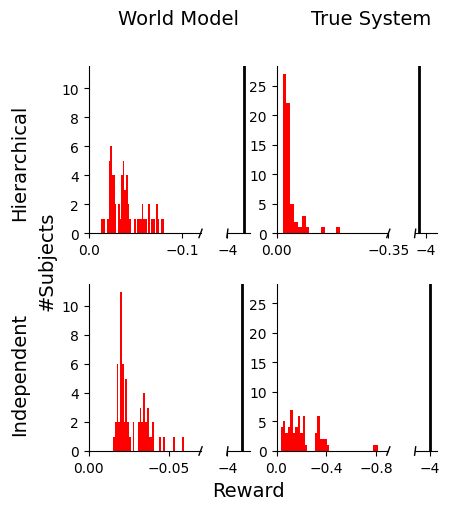

Figure saved to figures_new/sac_hier_lorenz_reward_comparison_combined_width_43_height_49.pdf


In [ ]:
# Create combined plot with both datasets side by side
fig = plt.figure(figsize=(4.5, 5))
gs = fig.add_gridspec(2, 4, height_ratios=[1, 1], width_ratios=[1, 0.2, 1, 0.2], hspace=0.3, wspace=0.4)

# LEFT SIDE: all_rewards_2
# Top row: broken axis for all_rewards_2
ax_top_left_1 = fig.add_subplot(gs[0, 0])
ax_top_right_1 = fig.add_subplot(gs[0, 1])
ax_top_left_1.hist(rewards_model[[4,  0,  8, 10,  1,  5]].mean(axis=(0, 2)), density=False, bins=40, color="red")
ax_top_right_1.hist(rewards_model[[4,  0,  8, 10,  1,  5]].mean(axis=(0, 2)), density=False, bins=40, color="red")

# Set limits and inversion for broken axis
ax_top_left_1.set_xlim(-0.12, 0)
ax_top_right_1.set_xlim(-4.5, -4)
ax_top_right_1.set_xticks([-4])
ax_top_left_1.invert_xaxis()
ax_top_right_1.invert_xaxis()
ax_top_right_1.axvline(-4.366, color='black', linewidth=2)
ax_top_left_1.set_xticks([0, -0.1])
ax_top_left_1.set_title("World Model", y=1.2, x=0.8, fontsize=FONT_SIZE)

# Hide spines between broken pair
ax_top_left_1.spines['right'].set_visible(False)
ax_top_right_1.spines['left'].set_visible(False)
ax_top_right_1.set_yticks([])

# Diagonal break markers
d = 0.025
kwargs = dict(transform=ax_top_left_1.transAxes, color='k', clip_on=False, linewidth=1)
ax_top_left_1.plot((1-d+0.011, 1+d-0.011), (-d, +d), **kwargs)
kwargs.update(transform=ax_top_right_1.transAxes)
ax_top_right_1.plot((-d, +d), (-d, +d), **kwargs)

# Styling
ax_top_left_1.spines['top'].set_visible(False)
ax_top_right_1.spines['top'].set_visible(False)
ax_top_right_1.spines['right'].set_visible(False)

# Bottom row: single intact axis for all_rewards_1
ax_bottom_left_1 = fig.add_subplot(gs[1, 0], sharey=ax_top_left_1)
ax_bottom_right_1 = fig.add_subplot(gs[1, 1], sharey=ax_top_right_1)
ax_bottom_left_1.hist(rewards_model_separate.mean(axis=(0, 2)), density=False, bins=40, color="red")
ax_bottom_right_1.hist(rewards_model_separate.mean(axis=(0, 2)), density=False, bins=40, color="red")
# Set limits and inversion for broken axis
ax_bottom_left_1.set_xlim(-0.07, 0)
ax_bottom_right_1.set_xlim(-5, -4.5)
ax_bottom_left_1.invert_xaxis()
ax_bottom_right_1.invert_xaxis()
ax_bottom_right_1.axvline(-4.654, color='black', linewidth=2)
ax_bottom_left_1.set_xticks([0, -0.05])
ax_bottom_right_1.set_xticks([-4])

ax_bottom_left_1.spines['right'].set_visible(False)
ax_bottom_right_1.spines['left'].set_visible(False)
ax_bottom_right_1.set_yticks([])

# Diagonal break markers
d = 0.025
kwargs = dict(transform=ax_bottom_left_1.transAxes, color='k', clip_on=False, linewidth=1)
ax_bottom_left_1.plot((1-d+0.011, 1+d-0.011), (-d, +d), **kwargs)
kwargs.update(transform=ax_bottom_right_1.transAxes)
ax_bottom_right_1.plot((-d, +d), (-d, +d), **kwargs)

# Styling
ax_bottom_left_1.spines['top'].set_visible(False)
ax_bottom_right_1.spines['top'].set_visible(False)
ax_bottom_right_1.spines['right'].set_visible(False)


ax_top_left_2 = fig.add_subplot(gs[0, 2])
ax_top_right_2 = fig.add_subplot(gs[0, 3])
ax_top_left_2.hist(np.where(rewards_true[[4, 0, 8, 10, 1, 5]]>-0.6, rewards_true[[4, 0, 8, 10, 1, 5]], -0.6).mean(axis=(0, 2)), density=False, bins=40, color="red")
ax_top_right_2.hist(np.where(rewards_true[[4, 0, 8, 10, 1, 5]]>-0.6, rewards_true[[4, 0, 8, 10, 1, 5]], -0.6).mean(axis=(0, 2)), density=False, bins=40, color="red")

# Set limits and inversion for broken axis
ax_top_left_2.set_xlim(0, -0.15)
ax_top_right_2.set_xticks([-4, -3])
ax_top_right_2.axvline(-3.47, color='black', linewidth=2)

# Hide spines between broken pair
ax_top_left_2.spines['right'].set_visible(False)
ax_top_right_2.spines['left'].set_visible(False)
ax_top_right_2.set_yticks([])
ax_top_left_2.set_xticks([])
ax_top_right_2.set_xticks([])

ax_top_left_2.set_xticks([0, -0.35])
ax_top_right_2.set_xticks([-4, -3])
ax_top_right_2.set_xlim(-3.1, -5)
ax_top_left_2.set_title("True System", y=1.2, x=0.85, fontsize=FONT_SIZE)

# Diagonal break markers
kwargs = dict(transform=ax_top_left_2.transAxes, color='k', clip_on=False, linewidth=1)
ax_top_left_2.plot((1-d+0.011, 1+d-0.011), (-d, +d), **kwargs)
kwargs.update(transform=ax_top_right_2.transAxes)
ax_top_right_2.plot((-d, +d), (-d, +d), **kwargs)

# Styling
ax_top_left_2.spines['top'].set_visible(False)
ax_top_right_2.spines['top'].set_visible(False)
ax_top_right_2.spines['right'].set_visible(False)

# Bottom row: single intact axis for all_rewards_1 (same data)
ax_bottom_left_2 = fig.add_subplot(gs[1, 2], sharey=ax_top_left_2)
ax_bottom_right_2 = fig.add_subplot(gs[1, 3], sharey=ax_top_right_2)

ax_bottom_left_2.hist(rewards_true_separate.mean(axis=(0, 2)), density=False, bins=40, color="red")
ax_bottom_right_2.hist(rewards_true_separate.mean(axis=(0, 2)), density=False, bins=40, color="red")

# Set limits and inversion for broken axis
ax_bottom_left_2.set_xlim(0, -0.9)
ax_bottom_right_2.set_xticks([-4, -3])
ax_bottom_right_2.axvline(-3.97, color='black', linewidth=2)

# Hide spines between broken pair
ax_bottom_left_2.spines['right'].set_visible(False)
ax_bottom_right_2.spines['left'].set_visible(False)
ax_bottom_right_2.set_yticks([])
ax_bottom_left_2.set_xticks([])
ax_bottom_right_2.set_xticks([])

ax_bottom_left_2.set_xticks([0, -0.4, -0.8])
ax_bottom_right_2.set_xticks([-4])
ax_bottom_right_2.set_xlim(-2, -5)

# Diagonal break markers
kwargs = dict(transform=ax_bottom_left_2.transAxes, color='k', clip_on=False, linewidth=1)
ax_bottom_left_2.plot((1-d+0.011, 1+d-0.011), (-d, +d), **kwargs)
kwargs.update(transform=ax_bottom_right_2.transAxes)
ax_bottom_right_2.plot((-d, +d), (-d, +d), **kwargs)

# Styling
ax_bottom_left_2.spines['top'].set_visible(False)
ax_bottom_right_2.spines['top'].set_visible(False)
ax_bottom_right_2.spines['right'].set_visible(False)


fig.text(-0.05, 0.15, "Independent", fontsize=FONT_SIZE, rotation="vertical")
fig.text(-0.05, 0.58, "Hierarchical", fontsize=FONT_SIZE, rotation="vertical")
fig.text(0.01, 0.40, "#Subjects", fontsize=FONT_SIZE, rotation="vertical")

# x label
fig.text(0.4, 0.02, "Reward", fontsize=FONT_SIZE)
plt.show()
#save_fig(fig, "sac_hier_lorenz_reward_comparison_combined")

In [ ]:
print(np.median(rewards_true.mean(axis=2), axis = 1)[[ 2,  4,  0,  8,  1,  9]].mean(), np.median(rewards_true.mean(axis=2), axis = 1)[[ 2,  4,  0,  8,  1,  9]].std())
print(np.median(rewards_true_separate.mean(axis=2), axis = 1).mean(), np.median(rewards_true_separate.mean(axis=2), axis = 1).std())
print(np.median(rewards_model.mean(axis=2), axis = 1)[[ 2,  4,  0,  8,  1,  9]].mean(), np.median(rewards_model.mean(axis=2), axis = 1)[[ 2,  4,  0,  8,  1,  9]].std())
print(np.median(rewards_model_separate.mean(axis=2), axis = 1).mean(), np.median(rewards_model_separate.mean(axis=2), axis = 1).std())

-0.040398035633067285 0.003682792002993409
-0.1701922676392964 0.01646549124078973
-0.0465522101148963 0.005928236424963708
-0.023243020874048982 0.0003598188329663503


## Analysis

In [ ]:
trial = get_trial_by_number(study.trials, 7)
trial_folder_name = "params_" + \
    "_".join([(f"{key}={ValueFormatter._formatted_value(value)}")
             for key, value in trial.params.items()])
print(trial_folder_name)

params_q_hidden1=38_policy_hidden1=31_env_steps_per_epoch=28_polyak_tau=0p00_q_lr=0p00_policy_lr=0p00_q_lr_gamma=1p00_policy_lr_gamma=1p00_aq=48p23_apolicy=140p12_areg_q=69p13_areg_policy=1p38_areg_temp=0p00_q_hidden2=38_policy_hidden2=18


In [ ]:
trial_folder_name = "params_q_hid1=29_policy_hid1=20_env_steps=14_polyak_tau=0p01_noise=0p00_q_lr=0p00_policy_lr=0p00_q_lr_gamma=1p00_policy_lr_gamma=1p00_aq=275p00_apolicy=34p46_areg_q=63p75_areg_policy=0p10_areg_temp=1p89_q_hid2=25_policy_hid2=18"
# 1 controlled
#trial_folder_name = "params_polyak_tau=0p01_q_lr=0p00_policy_lr=0p00_q_lr_gamma=1p00_policy_lr_gamma=1p00_aq=139p17_apolicy=57p77_areg_q=18p86_areg_policy=33p06_areg_temp=0p01"
#trial_folder_name = "params_q_hid1=18_policy_hid1=38_env_steps=25_polyak_tau=0p00_noise=0p04_q_lr=0p00_policy_lr=0p00_q_lr_gamma=1p00_policy_lr_gamma=1p00_aq=450p38_apolicy=138p97_areg_q=97p10_areg_policy=57p07_areg_temp=0p00_q_hid2=16_policy_hid2=37"
# set up model
run_path = os.path.join(RESULTS_PATH, trial_folder_name, RUN)


parameters = json.load(open(f"{run_path}/config.json"))
mtf_parameters = json.load(open(f"{parameters["world_model"]["path"]}/config.json"))
model = MTF_SAC_Model(DATASET, model_path=run_path, device=DEVICE)

subject_vectors = model.dsr_model.latent_step_params.subject_vectors.detach().cpu().numpy()

Encoder model parameters: 5888
DSR model parameters: 3168
Decoder model parameters: 0
SAC model parameters: 17296


In [ ]:
true_system = True 

observed_trajectory_all = []
latent_trajectory_all = []
actions_all = []
value_function_all = []

for measurement_index in range(64):
    data = DATASET.evaluator_test_samples[measurement_index*TIME_SERIES_PER_MEASUREMENT].input

    observed_trajectory_cat = []
    latent_trajectory_cat = []
    actions_cat = []
    apply_actions = False

    for _ in range(6):
        T = T_DYNAMICS if not apply_actions else T_CONTROL
        if true_system:
            observed_trajectory, latent_trajectory, actions = integrate_controlled_lorenz(model, data[0], measurement_index, MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index], T=T, apply_actions=apply_actions, expected=True)
        else:
            cumulative_timeseries_index = MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index]
            (observed_trajectory,
            latent_trajectory,
            actions,
            _,
            _,
            _,
            _,
            _) = model.generate_free_trajectory(
                    data,
                    cumulative_timeseries_index,  # One trajectory per subject
                    measurement_index,
                    apply_actions=apply_actions,
                    T=T, 
                    expected =True,
            )
        apply_actions = not apply_actions
        data = tc.tile(observed_trajectory[0, -1], dims=(T, 1))
        actions_cat.append(actions[0])
        observed_trajectory_cat.append(observed_trajectory[0, :-1])
        latent_trajectory_cat.append(latent_trajectory[0, :-1])
        
    observed_trajectory_all.append(tc.cat(observed_trajectory_cat, dim=0))
    actions_all.append(tc.cat(actions_cat, dim=0))
    latent_trajectory_all.append(tc.cat(latent_trajectory_cat, dim=0))
    
    value_function = compute_value_function(model, latent_trajectory_all[-1], measurement_index, MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index], n_samples=2)
    value_function_all.append(value_function)

tensor(-0.0339) tensor(0.0114)


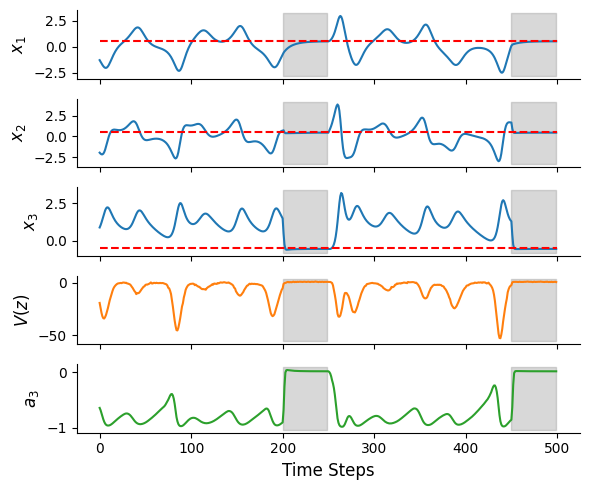

Figure saved to figures_new/sac_hier_true_lorenz_example_53_width_57_height_47.pdf


In [ ]:
measurement_index = 53
reward = model.reward_function(observed_trajectory_all[measurement_index][200:250].unsqueeze(0), actions_all[measurement_index][200:250], measurement_index).detach().squeeze()[15:]
print(reward.mean(), reward.std())

fig, axs = plt.subplots(5, 1, figsize=(6, 5), sharex=True)
axs[0].plot(observed_trajectory_all[measurement_index][:500, 0].detach())
axs[1].plot(observed_trajectory_all[measurement_index][:500, 1].detach())
axs[2].plot(observed_trajectory_all[measurement_index][:500, 2].detach())
axs[3].plot(value_function_all[measurement_index][:500].detach(), c='C1')

if true_system:
    axs[4].plot(actions_all[measurement_index][:500, 2].detach(),  c='C2')
    axs[4].set_ylabel(r"$a_3$", fontsize=FONT_SIZE)
else:
    indices_lsr, all_lsr = compute_actived_linear_subregions(latent_trajectory_all[measurement_index], model.dsr_model.hyperparameters["relu_units"])
    axs[4].plot(indices_lsr[:500], c='C4')
    axs[4].set_ylabel("LSR", fontsize=FONT_SIZE)


axs[0].set_ylabel(r"$x_1$", fontsize=FONT_SIZE)
axs[1].set_ylabel(r"$x_2$", fontsize=FONT_SIZE)
axs[2].set_ylabel(r"$x_3$", fontsize=FONT_SIZE)
axs[3].set_ylabel(r"$V(z)$", fontsize=FONT_SIZE)
axs[4].set_xlabel("Time Steps", fontsize=FONT_SIZE)

for ax in axs:
    ax.fill_between(x=np.arange(len(CONTROL_STATUS[:500])), y1=ax.get_ylim()[0], y2=ax.get_ylim()[1], where=(CONTROL_STATUS[:500]==1), color='gray', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
for k, ax in enumerate(axs[:3]):
    ax.hlines(y=GOAL_STATE[k].item(), color='r', xmin=0, xmax=observed_trajectory_all[0][:500].shape[0], linestyles='dashed')
    
plt.tight_layout()
plt.show()
#save_fig(fig, "sac_hier_{}_lorenz_example_{}".format("true" if true_system else "sim", measurement_index))

In [ ]:
n_lsr_90_all = []
n_lsr_90_uncontrolled_all = []
fp_lsr_all = []

for measurement_index in range(64):
    cumulative_timeseries_index = MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index]
    
    indices_lsr, all_lsr = compute_actived_linear_subregions(latent_trajectory_all[measurement_index], model.dsr_model.hyperparameters["relu_units"])
    
    hist, _ = np.histogram(indices_lsr[CONTROL_STATUS==1].numpy(), bins=np.arange(all_lsr.shape[0]+1)-0.5, density=False)
    # determine how many lsr are necessary to cover 95% of the controlled time steps
    sorted_hist = np.sort(hist)[::-1]
    cumsum = np.cumsum(sorted_hist)
    n_lsr_90 = np.argwhere(cumsum >= 0.90 * cumsum[-1])[0][0] + 1
    n_lsr_90_all.append(n_lsr_90)
    
    hist, _ = np.histogram(indices_lsr[CONTROL_STATUS==0].numpy(), bins=np.arange(all_lsr.shape[0]+1)-0.5, density=False)
    # determine how many lsr are necessary to cover 95% of the controlled time steps
    sorted_hist = np.sort(hist)[::-1]
    cumsum = np.cumsum(sorted_hist)
    n_lsr_90 = np.argwhere(cumsum >= 0.90 * cumsum[-1])[0][0] + 1
    n_lsr_90_uncontrolled_all.append(n_lsr_90)
    
    policy_params = model.dsr_sac_model.sac_construct_params(cumulative_timeseries_index, model.dsr_sac_model.policy_params, "policy")
    latent_step_params = model.dsr_model.construct_params(cumulative_timeseries_index=cumulative_timeseries_index)
    relu_units =  model.dsr_model.hyperparameters["relu_units"]
    
    fp_lsr = []    
    for i, lsr in enumerate(all_lsr):
        for k in range(500):
            if k ==0:
                state = latent_trajectory_all[measurement_index][240].clone()
            else:
                state = tc.randn(26)*2
            # make state consistent with LSR
            state[-relu_units:][lsr] = tc.abs(state[-relu_units:][lsr])
            state[-relu_units:][~lsr] = -tc.abs(state[-relu_units:][~lsr])

            # sample random action 
            action, ll = model.dsr_sac_model.sample_action(state.unsqueeze(0), policy_params, measurement_index, expected=True)
            action = tc.randn_like(action)*0.1
            action[:, 0] = 0
            latent_action = tc.nn.functional.pad(action.squeeze(), (0, 26 - actions_all[measurement_index].shape[1]))
            
            # check if the dynamics remains in the same LSR after applying the action
            remains_in_lsr = ((model.dsr_sac_model.generate_free_trajectory(state.unsqueeze(0)+latent_action, 1, cumulative_timeseries_index, measurement_index,S=[None], apply_actions=False)[0][0, 1, -relu_units:]>0)    == (state[-relu_units:]>0)).all()
            
            # compute jacobian and fixed point
            jacobian = model.dsr_model.latent_step.jacobian(state.unsqueeze(0), latent_step_params, model.dsr_model.hyperparameters)[0]        
            fixed_point = tc.linalg.inv(tc.eye(26) - jacobian)@(latent_step_params["h"][0] + jacobian@latent_action)

            # check if the fixed point is virtual
            fp_in_lsr = ((fixed_point[-relu_units:]>0)    == (state[-relu_units:]>0)).all()
            fp_distance = tc.linalg.norm(fixed_point[:3] - GOAL_STATE).cpu().item()**2

            if fp_distance <10 and fp_in_lsr:
                fp_lsr.append([i, tc.norm(action).item(), fp_distance])
                
    fp_lsr_all.append(np.array(fp_lsr))
    
fp_distances_90_all = []
fp_distances_uncontrolled_all = []
eigenvals_90_all = []
for measurement_index in range(64):
    indices_lsr, all_lsr = compute_actived_linear_subregions(latent_trajectory_all[measurement_index], model.dsr_model.hyperparameters["relu_units"])
    unique, counts = np.unique(indices_lsr[CONTROL_STATUS==1].numpy(), return_counts=True)
    idx_sorted = np.argsort(counts)[::-1]
    cumsum = np.cumsum(counts[idx_sorted])
    idx_90 = np.argwhere(cumsum >= 0.90 * cumsum[-1])[0][0] + 1
    try:
        a = np.min([fp_lsr_all[measurement_index][i][2] for i in range(len(fp_lsr_all[measurement_index])) if fp_lsr_all[measurement_index][i][0] in unique[idx_sorted[:idx_90]]])
        
        fp_distances_90_all.append(a)
    except:
        fp_distances_90_all.append(np.nan)
    b = np.min([fp_lsr_all[measurement_index][i][2] for i in range(len(fp_lsr_all[measurement_index])) if fp_lsr_all[measurement_index][i][0] not in unique])
    fp_distances_uncontrolled_all.append(b)

    eigenvals_90 = []
    for i, lsr in enumerate(all_lsr):
        # use only LSR if it is among the 90% most frequent controlled LSR and where a fixed point was found
        if not i in fp_lsr_all[measurement_index][:, 0] or not i in unique[idx_sorted[:idx_90]]: continue
        # jacobian only depends on LSR, so use arbitrary state in LSR
        state[-relu_units:][lsr] = tc.abs(state[-relu_units:][lsr])
        state[-relu_units:][~lsr] = -tc.abs(state[-relu_units:][~lsr])
        jacobian = model.dsr_model.latent_step.jacobian(state.unsqueeze(0), latent_step_params, model.dsr_model.hyperparameters)[0]        

            
        eigenvals_90.append(tc.linalg.eigvals(jacobian).cpu().numpy())
    eigenvals_90_all.append(np.array(eigenvals_90))

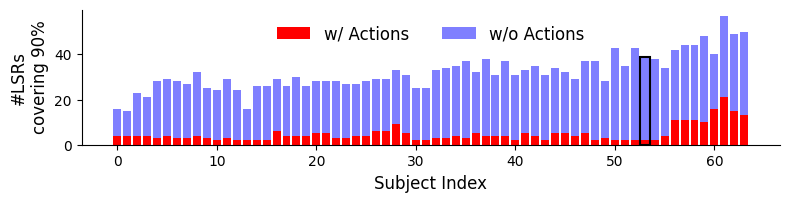

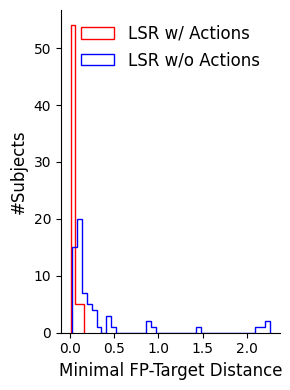

Figure saved to figures_new/sac_hier_sim_lorenz_fp_distance_90_summary_width_27_height_37.pdf


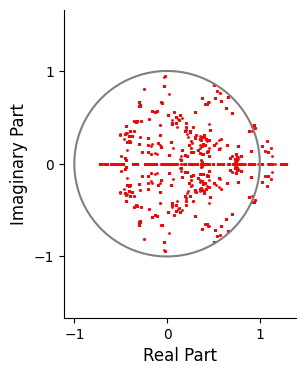

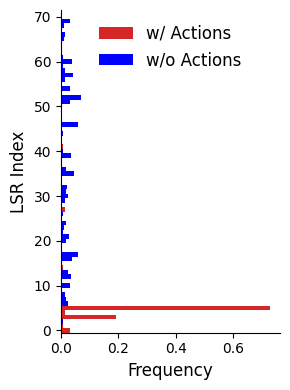

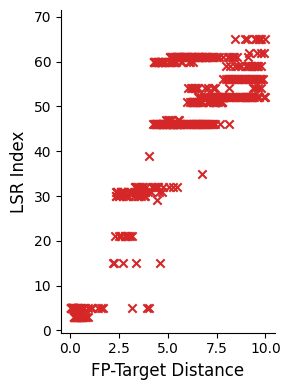

In [ ]:
measurement_index = 53
indices_lsr, all_lsr = compute_actived_linear_subregions(latent_trajectory_all[measurement_index], model.dsr_model.hyperparameters["relu_units"])

# Figure 1
fig1, ax1 = plt.subplots(figsize=(8, 2.125))
ax1.bar(np.arange(64), n_lsr_90_all, color="red")
ax1.bar(np.arange(64), n_lsr_90_uncontrolled_all, bottom=n_lsr_90_all, color='blue', alpha=0.5)
ax1.legend(["w/ Actions", "w/o Actions"], fontsize=FONT_SIZE, frameon=False, ncol=2, loc='upper center')
ax1.add_patch(plt.Rectangle((measurement_index-0.5, 0), 1, n_lsr_90_all[53] + n_lsr_90_uncontrolled_all[53], fill=False, edgecolor='black', lw=1.5))
ax1.set_ylabel("#LSRs\ncovering 90%", fontsize=FONT_SIZE)
ax1.set_xlabel("Subject Index", fontsize=FONT_SIZE)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
fig1.tight_layout()
plt.show()
#save_fig(fig1, "sac_hier_sim_lorenz_nlsr_90_summary")

# Figure 2
fig2, ax2 = plt.subplots(figsize=(3, 4))
ax2.hist(fp_distances_90_all, bins=3, color="red", density=False, histtype='step')
ax2.hist(fp_distances_uncontrolled_all, bins=40, color="blue", density=False, histtype='step')
ax2.legend(["LSR w/ Actions", "LSR w/o Actions"], fontsize=FONT_SIZE, frameon=False, ncol=1, loc='upper center')
#ax2.add_patch(plt.Rectangle((measurement_index-0.5, 0), 1, fp_distances_90[53]*5, fill=False, edgecolor='black', lw=1.5))
ax2.set_xlabel("Minimal FP-Target Distance", fontsize=FONT_SIZE)
ax2.set_ylabel("#Subjects", fontsize=FONT_SIZE)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
fig2.tight_layout()
plt.show()
#save_fig(fig2, "sac_hier_sim_lorenz_fp_distance_90_summary")

fig3, ax3 = plt.subplots(figsize=(3, 4))
for measurement_index_ in range(64):
    for i in range(len(eigenvals_90_all[measurement_index_])):
        ax3.scatter(eigenvals_90_all[measurement_index_][i].real, eigenvals_90_all[measurement_index_][i].imag,color="red", s=1)
# plot unit circle
theta = np.linspace(0, 2*np.pi, 100)
x = np.cos(theta)
y = np.sin(theta)
ax3.plot(x, y, color='gray')
ax3.axis('equal')

ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.set_xlabel("Real Part", fontsize=FONT_SIZE)
ax3.set_ylabel("Imaginary Part", fontsize=FONT_SIZE)
ax3.set_yticks([-1, 0, 1])
plt.show()
#save_fig(fig3, "sac_hier_sim_lorenz_eigenvalues_fp_90_summary")

# Figure 3
fig4, ax4 = plt.subplots(figsize=(3, 4))
bins, edges, _ = ax4.hist(indices_lsr[CONTROL_STATUS==1].numpy(), bins=np.arange(all_lsr.shape[0]+1)-0.5, density=True, color='C3', orientation='horizontal')
bins, edges, _ = ax4.hist(indices_lsr[CONTROL_STATUS==0].numpy(), bins=np.arange(all_lsr.shape[0]+1)-0.5, density=True, color='blue', orientation='horizontal')
ax4.set_ylabel("LSR Index", fontsize=FONT_SIZE)
ax4.set_xlabel("Frequency", fontsize=FONT_SIZE)
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.set_ylim(-0.5, all_lsr.shape[0]-0.5)
ax4.legend(["w/ Actions", "w/o Actions"], fontsize=FONT_SIZE, frameon=False, ncol=1, loc='upper center')
fig4.tight_layout()
plt.show()
#save_fig(fig4, "sac_hier_sim_lorenz_nlsr_hist_subject_53")

# Figure 5
fig5, ax5 = plt.subplots(figsize=(3, 4))
ax5.scatter(fp_lsr_all[measurement_index][:, 2], fp_lsr_all[measurement_index][:, 0],c='C3', marker='x')
ax5.set_ylabel("LSR Index", fontsize=FONT_SIZE)
ax5.set_xlabel("FP-Target Distance", fontsize=FONT_SIZE)
ax5.set_ylim(-0.5, all_lsr.shape[0]-0.5)
ax5.spines['top'].set_visible(False)
ax5.spines['right'].set_visible(False)
fig5.tight_layout()
plt.show()
#save_fig(fig5, "sac_hier_sim_lorenz_fp_distance_subject_53")

In [ ]:
# does the same as the first cell that generates trajectories, but only for one measurement and with longer controlled trajectories for visualization purposes
true_system = False 

measurement_index = 53
cumulative_timeseries_index = MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index]

data = DATASET.evaluator_test_samples[measurement_index*TIME_SERIES_PER_MEASUREMENT].input

latent_trajectory_cat = []
actions_cat = []
apply_actions = False

for _ in range(2):
    T = T_DYNAMICS if not apply_actions else T_CONTROL +100
    
    (observed_trajectory,
    latent_trajectory,
    actions,
    _,
    _,
    _,
    _,
    _) = model.generate_free_trajectory(
            data,
            cumulative_timeseries_index,  # One trajectory per subject
            measurement_index,
            apply_actions=apply_actions,
            T=T, 
            expected =True,
    )
    apply_actions = not apply_actions
    data = tc.tile(observed_trajectory[0, -1], dims=(T, 1))
    actions_cat.append(actions[0])
    latent_trajectory_cat.append(latent_trajectory[0, :-1])

latent_trajectory_cat = tc.cat(latent_trajectory_cat)
actions_cat = tc.cat(actions_cat)


# generate plot that shows the fixed point distance as well as the trajectory distance to the goal state across time 
indices_lsr, all_lsr = compute_actived_linear_subregions(latent_trajectory_cat, model.dsr_model.hyperparameters["relu_units"])
policy_params = model.dsr_sac_model.sac_construct_params(cumulative_timeseries_index, model.dsr_sac_model.policy_params, "policy")
latent_step_params = model.dsr_model.construct_params(cumulative_timeseries_index=cumulative_timeseries_index)
relu_units =  model.dsr_model.hyperparameters["relu_units"]

fp_across_time = []
for time_step in range(200, 300):
    fp = []    
    lsr = all_lsr[np.bincount(indices_lsr).argmax()]
    
    for scale in np.linspace(0, 2, 100):
        state = latent_trajectory_cat[time_step].clone()

        # make state consistent with LSR
        if not tc.equal(state[-relu_units:][lsr], tc.abs(state[-relu_units:][lsr])) or not tc.equal(state[-relu_units:][~lsr], -tc.abs(state[-relu_units:][~lsr])):
            break

        # sample random action 
        action, ll = model.dsr_sac_model.sample_action(state.unsqueeze(0), policy_params, measurement_index, expected=True)
        action = scale *action
        action[:, 0] = 0
        latent_action = tc.nn.functional.pad(action.squeeze(), (0, 26 - actions_cat.shape[1]))
        
        # check if the dynamics remains in the same LSR after applying the action
        remains_in_lsr = ((model.dsr_sac_model.generate_free_trajectory(state.unsqueeze(0)+latent_action, 1, cumulative_timeseries_index, measurement_index,S=[None], apply_actions=False)[0][0, 1, -relu_units:]>0)    == (state[-relu_units:]>0)).all()
        
        # compute jacobian and fixed point
        jacobian = model.dsr_model.latent_step.jacobian(state.unsqueeze(0), latent_step_params, model.dsr_model.hyperparameters)[0]        
        fixed_point = tc.linalg.inv(tc.eye(26) - jacobian)@(latent_step_params["h"][0] + jacobian@latent_action)

        # check if the fixed point is virtual
        fp_in_lsr = ((fixed_point[-relu_units:]>0)    == (state[-relu_units:]>0)).all()
        fp_distance = tc.linalg.norm(fixed_point[:3] - GOAL_STATE).cpu().item()**2

        if fp_distance <5 and fp_in_lsr and remains_in_lsr:
            fp.append([scale, fp_distance])
                
    fp = np.array(fp)
    fp_across_time.append(fp)


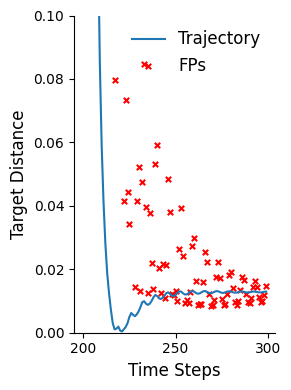

Figure saved to figures_new/sac_hier_sim_lorenz_fp_distance_across_time_subject_53_width_27_height_37.pdf


In [ ]:
fig = plt.figure(figsize=(3, 4))

t_start = 200
t_end=300
plt.plot(range(t_start, t_end), ((latent_trajectory_cat[t_start:t_end][:, :3] - GOAL_STATE).norm(dim=1)**2).detach().numpy(), label="Trajectory")
#plt.plot(range(t_start, t_end), indices_lsr[t_start:t_end]/80)

for i in range(100):
    if len(fp_across_time[i])==0:continue
    fp = fp_across_time[i]
    
    #plt.scatter(i+t_start, fp[:, 1].min(), c="red", s=10)
    plt.scatter(i+t_start, fp[:, 1][np.abs(fp[:, 0]-1).argmin()], c="red", s=15, label="FPs" if i==99 else "", marker="x")
    
plt.ylim(0, 0.1)
plt.ylabel("Target Distance", fontsize=FONT_SIZE)
plt.xlabel("Time Steps", fontsize=FONT_SIZE)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.legend(fontsize=FONT_SIZE, frameon=False)
plt.tight_layout()
plt.show()
#save_fig(fig, "sac_hier_sim_lorenz_fp_distance_across_time_subject_{}".format(measurement_index))

In [ ]:
align_pdf_figures([
    FIG_DIR + "/sac_hier_lorenz_reward_comparison_combined_width_43_height_49.pdf",
    FIG_DIR + "/sac_hier_true_lorenz_example_53_width_57_height_47.pdf",
    FIG_DIR + "/sac_hier_sim_lorenz_nlsr_hist_subject_53_width_27_height_37.pdf",
    FIG_DIR + "/sac_hier_sim_lorenz_fp_distance_subject_53_width_27_height_37.pdf",
],
    output_pdf="combined_figures2.pdf",
    rows=1,
)

PosixPath('figures_new/combined_figures2.pdf')

In [ ]:
align_pdf_figures([
    FIG_DIR + "/sac_hier_sim_lorenz_example_53_width_57_height_47.pdf",
    FIG_DIR + "/sac_hier_sim_lorenz_nlsr_90_summary_width_77_height_18.pdf",
    FIG_DIR + "/sac_hier_sim_lorenz_fp_distance_90_summary_width_27_height_37.pdf",
    FIG_DIR + "/sac_hier_sim_lorenz_eigenvalues_fp_90_summary_width_28_height_35.pdf",
    FIG_DIR + "/sac_hier_sim_lorenz_fp_distance_across_time_subject_53_width_27_height_37.pdf",
],
    output_pdf="combined_figures6.pdf",
    rows=2,
)

PosixPath('figures_new/combined_figures6.pdf')

In [ ]:
align_pdf_figures([
    FIG_DIR + "/sac_hier_true_ft_lorenz_2_dim_example_53_width_77_height_50.pdf",
    FIG_DIR + "/hier_lorenz_subject_vectors_ft_width_54_height_35.pdf",
],
    output_pdf="combined_figures7.pdf",
    rows=1,
)

PosixPath('figures_new/combined_figures7.pdf')

## Parameter Count

In [ ]:
# count all trainable parameters of the model and print their name
total_params_hier = 0
for name, param in model.named_parameters():
    if param.requires_grad:
        total_params_hier += param.numel()
        print(f"{name}: {param.numel()}")

total_params_q_sep = 0
for key, param in model.dsr_sac_model.sac_construct_params(0, model.dsr_sac_model.q1_params, "q").items():
    total_params_q_sep += param.numel()

total_params_q2_sep = 0
for key, param in model.dsr_sac_model.sac_construct_params(0, model.dsr_sac_model.q2_params, "q").items():
    total_params_q2_sep += param.numel()

total_params_pol_sep = 0
for key, param in model.dsr_sac_model.sac_construct_params(0, model.dsr_sac_model.policy_params, "policy").items():
    total_params_pol_sep += param.numel()

1-(total_params_hier)/(64*(total_params_q_sep + total_params_q2_sep + total_params_pol_sep))

dsr_sac_model.policy_params.group.PW_0: 2080
dsr_sac_model.policy_params.group.PW_1: 1440
dsr_sac_model.policy_params.group.PW_2: 432
dsr_sac_model.policy_params.group.Pb_0: 80
dsr_sac_model.policy_params.group.Pb_1: 72
dsr_sac_model.policy_params.group.Pb_2: 24
dsr_sac_model.q1_params.group.PW_0: 3364
dsr_sac_model.q1_params.group.PW_1: 2900
dsr_sac_model.q1_params.group.PW_2: 100
dsr_sac_model.q1_params.group.Pb_0: 116
dsr_sac_model.q1_params.group.Pb_1: 100
dsr_sac_model.q1_params.group.Pb_2: 4
dsr_sac_model.q2_params.group.PW_0: 3364
dsr_sac_model.q2_params.group.PW_1: 2900
dsr_sac_model.q2_params.group.PW_2: 100
dsr_sac_model.q2_params.group.Pb_0: 116
dsr_sac_model.q2_params.group.Pb_1: 100
dsr_sac_model.q2_params.group.Pb_2: 4


0.9375

## Fine Tuning

In [ ]:
from src.models.mtf_model import MTFModel
from copy import deepcopy

GOAL_STATE = tc.tensor([0.5, 0.5, -0.5])
T_DYNAMICS = 200
T_CONTROL = 50
CONTROL_STATUS = np.concatenate(([0]*T_DYNAMICS, [1]*T_CONTROL)*3)
RESULTS_PATH = os.path.join(RESULTS_DIR, "hier_lorenz_ft")
RUN = "001"
DEVICE = tc.device("cpu")
DATASET_FT = init_dataset(json.load(open(RESULTS_PATH + "/params_dsr_lr=0p03_lr_gamma=1p00_gtf=0p00_gtf_gamma=1p00_aent=14p17_adsr=39p07_ac=2p13_asc=0p00_alpha_mar=0p00/001/config.json")), DEVICE)
MEASUREMENT_INDEX_TO_TS_INDEX_FT = {DATASET_FT.evaluator_test_samples[i].measurement_index: DATASET_FT.evaluator_test_samples[i].cumulative_timeseries_index for i in range(len(DATASET_FT.evaluator_test_samples)-1, -1, -1)}

Sequence length set to 30.


In [ ]:
# load test set
full_ft = tc.as_tensor(np.load(DATA_DIR + "/multi_task_lorenz63/no_spirals/full_FT.npy", allow_pickle=True)).permute(1, 0, 2)

trial_folder_name = "params_dsr_lr=0p03_lr_gamma=1p00_gtf=0p00_gtf_gamma=1p00_aent=14p17_adsr=39p07_ac=2p13_asc=0p00_alpha_mar=0p00"
# set up model
run_path = os.path.join(RESULTS_PATH, trial_folder_name, RUN)

world_model_parameters_ft = json.load(open(f"{run_path}/config.json"))
world_model_ft = MTFModel(DATASET_FT, model_path=run_path, device=DEVICE)
# copy model 
model_ft = deepcopy(model)

model_ft.dsr_sac_model.latent_step_params.subject_vectors = world_model_ft.dsr_model.latent_step_params.subject_vectors
model_ft.dsr_sac_model.policy_params.subject_vectors = world_model_ft.dsr_model.latent_step_params.subject_vectors
model_ft.dsr_sac_model.q1_params.subject_vectors = world_model_ft.dsr_model.latent_step_params.subject_vectors 
model_ft.dsr_sac_model.q2_params.subject_vectors = world_model_ft.dsr_model.latent_step_params.subject_vectors
model_ft.encoder_model.encoder_params.subjects = world_model_ft.encoder_model.encoder_params.subjects

Encoder model parameters: 5888
DSR model parameters: 3168
Decoder model parameters: 0


In [ ]:
true_system = True 

observed_trajectory_all_ft = []
latent_trajectory_all_ft = []
actions_all_ft = []
value_function_all_ft = []

for measurement_index in range(64):
    data = DATASET_FT.evaluator_test_samples[measurement_index*TIME_SERIES_PER_MEASUREMENT].input

    observed_trajectory_cat = []
    latent_trajectory_cat = []
    actions_cat = []
    apply_actions = False

    for _ in range(6):
        T = T_DYNAMICS if not apply_actions else T_CONTROL
        if true_system:
            observed_trajectory, latent_trajectory, actions = integrate_controlled_lorenz(model_ft, data[0], measurement_index, MEASUREMENT_INDEX_TO_TS_INDEX_FT[measurement_index], T=T, apply_actions=apply_actions, expected=True, fine_tuning_params=True)
        else:
            cumulative_timeseries_index = MEASUREMENT_INDEX_TO_TS_INDEX_FT[measurement_index]
            (observed_trajectory,
            latent_trajectory,
            actions,
            _,
            _,
            _,
            _,
            _) = model_ft.generate_free_trajectory(
                    data,
                    cumulative_timeseries_index,  # One trajectory per subject
                    measurement_index,
                    apply_actions=apply_actions,
                    T=T, 
                    expected =True,
            )
        apply_actions = not apply_actions
        data = tc.tile(observed_trajectory[0, -1], dims=(T, 1))

        actions_cat.append(actions[0])
        observed_trajectory_cat.append(observed_trajectory[0, :-1])
        latent_trajectory_cat.append(latent_trajectory[0, :-1])
        
    observed_trajectory_all_ft.append(tc.cat(observed_trajectory_cat, dim=0))
    actions_all_ft.append(tc.cat(actions_cat, dim=0))
    latent_trajectory_all_ft.append(tc.cat(latent_trajectory_cat, dim=0))
    
    
    value_function = compute_value_function(model, latent_trajectory_all_ft[-1], measurement_index, MEASUREMENT_INDEX_TO_TS_INDEX_FT[measurement_index], n_samples=2)
    value_function = (value_function - value_function.min()) / (value_function.max() - value_function.min())
    value_function_all_ft.append(value_function)

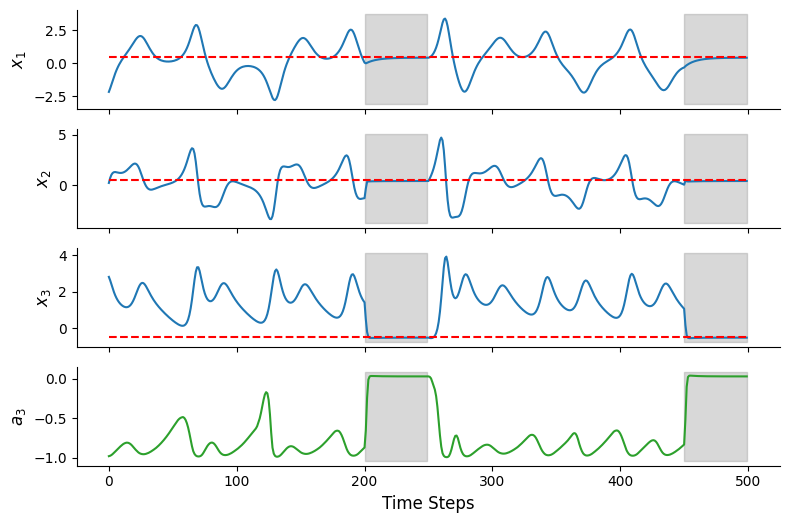

In [ ]:
assert true_system == True
measurement_index = 53


fig, axs = plt.subplots(4, 1, figsize=(8, 5.33), sharex=True)
axs[0].plot(observed_trajectory_all_ft[measurement_index][:500, 0].detach())
axs[1].plot(observed_trajectory_all_ft[measurement_index][:500, 1].detach())
axs[2].plot(observed_trajectory_all_ft[measurement_index][:500, 2].detach())

axs[3].plot(actions_all_ft[measurement_index][:500, 2].detach(), label=r"$a_X$", c='C2')

axs[0].set_ylabel(r"$x_1$", fontsize=FONT_SIZE)
axs[1].set_ylabel(r"$x_2$", fontsize=FONT_SIZE)
axs[2].set_ylabel(r"$x_3$", fontsize=FONT_SIZE)
axs[3].set_ylabel(r"$a_3$", fontsize=FONT_SIZE)
axs[3].set_xlabel("Time Steps", fontsize=FONT_SIZE)

for ax in axs:
    ax.fill_between(x=np.arange(len(CONTROL_STATUS[:500])), y1=ax.get_ylim()[0], y2=ax.get_ylim()[1], where=(CONTROL_STATUS[:500]==1), color='gray', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
for k, ax in enumerate(axs[:3]):
    ax.hlines(y=GOAL_STATE[k].item(), color='r', xmin=0, xmax=observed_trajectory_all_ft[0][:500].shape[0], linestyles='dashed')
    
plt.tight_layout()
plt.show()
#save_fig(fig, "sac_hier_true_ft_lorenz_2_dim_example_53")

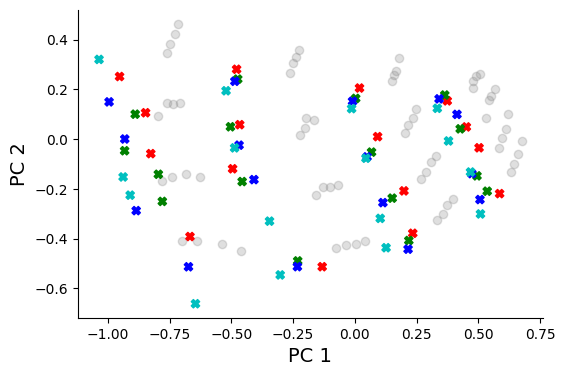

Figure saved to figures_new/hier_lorenz_subject_vectors_ft_width_54_height_35.pdf


In [ ]:
colors = ["r", "g", "b", "c"]*16
#colors = ["r", "r", "r", "r", "g", "g", "g", "g", "b", "b", "b", "b", "c", "c", "c", "c"]*4
#colors = ["r"]*16 + ["g"]*16 + ["b"]*16 + ["c"]*16

fig = plt.figure(figsize=(6, 4))
    
pca = PCA(n_components=2)
subject_vectors = model.dsr_model.latent_step_params.subject_vectors.detach().cpu().numpy()
subject_vectors_2d = pca.fit_transform(subject_vectors)
plt.scatter(subject_vectors_2d[:, 0], subject_vectors_2d[:, 1], c="grey",  alpha=0.25)
#pca = PCA(n_components=2)
subject_vectors = model_ft.dsr_sac_model.policy_params.subject_vectors.detach().cpu().numpy()
subject_vectors_2d = pca.transform(subject_vectors)
plt.scatter(subject_vectors_2d[:, 0], subject_vectors_2d[:, 1], c=colors, marker="X")

plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.xlabel("PC 1", fontsize=FONT_SIZE)
plt.ylabel("PC 2", fontsize=FONT_SIZE)     
plt.show() 
#save_fig(fig, "hier_lorenz_subject_vectors_ft")

In [ ]:
RESULTS_PATH = os.path.join(RESULTS_DIR, "hier_lorenz_sac_2")
trial_folder_name = "params_q_hid1=29_policy_hid1=20_env_steps=14_polyak_tau=0p01_noise=0p00_q_lr=0p00_policy_lr=0p00_q_lr_gamma=1p00_policy_lr_gamma=1p00_aq=275p00_apolicy=34p46_areg_q=63p75_areg_policy=0p10_areg_temp=1p89_q_hid2=25_policy_hid2=18"
runs = sorted(os.listdir(os.path.join(RESULTS_PATH, trial_folder_name)))[:10]

rewards_true_ft = np.zeros((len(runs), 64, 10))
rewards_model_ft = np.zeros((len(runs), 64, 10))
rewards_true_ft_old_subjects = np.zeros((len(runs), 64, 10))
rewards_model_ft_old_subjects = np.zeros((len(runs), 64, 10))

for k, run in enumerate(runs):
    run_path = os.path.join(RESULTS_PATH, trial_folder_name, run)
    model_ft = MTF_SAC_Model(DATASET_FT, model_path=run_path, device=DEVICE)
    model_ft.dsr_sac_model.latent_step_params.subject_vectors = world_model_ft.dsr_model.latent_step_params.subject_vectors
    
    tc.manual_seed(1)
    for measurement_index in range(64):        
        for i in range(10):
            x0 = DATASET_FT.evaluator_test_samples[measurement_index*TIME_SERIES_PER_MEASUREMENT].input[tc.randint(0, 200, (1,))][0]
            
            observed_trajectory, _, actions = integrate_controlled_lorenz(model_ft, x0, measurement_index, MEASUREMENT_INDEX_TO_TS_INDEX_FT[measurement_index], T=500, apply_actions=True, expected=True, fine_tuning_params=True)
            rewards_true_ft_old_subjects[k, measurement_index, i] = model_ft.reward_function(observed_trajectory[:, 1:], actions, measurement_index).detach().squeeze()[15:].mean()

            cumulative_timeseries_index = MEASUREMENT_INDEX_TO_TS_INDEX_FT[measurement_index]
            (observed_trajectory,
            _,
            actions,
            _,
            _,
            _,
            _,
            _) = model_ft.generate_free_trajectory(
                    x0.unsqueeze(0),
                    cumulative_timeseries_index,
                    measurement_index,
                    apply_actions=True,
                    T=500, 
                    expected =True,
            )
            
            rewards_model_ft_old_subjects[k, measurement_index, i] = model_ft.reward_function(observed_trajectory[:, :-1], actions, measurement_index).detach().squeeze()[15:].mean()
    
    model_ft.dsr_sac_model.policy_params.subject_vectors = world_model_ft.dsr_model.latent_step_params.subject_vectors
    model_ft.dsr_sac_model.q1_params.subject_vectors = world_model_ft.dsr_model.latent_step_params.subject_vectors 
    model_ft.dsr_sac_model.q2_params.subject_vectors = world_model_ft.dsr_model.latent_step_params.subject_vectors

    tc.manual_seed(1)
    for measurement_index in range(64):
        for i in range(10):
            x0 = DATASET_FT.evaluator_test_samples[measurement_index*TIME_SERIES_PER_MEASUREMENT].input[tc.randint(0, 200, (1,))][0]
            observed_trajectory, _, actions = integrate_controlled_lorenz(model_ft, x0, measurement_index, MEASUREMENT_INDEX_TO_TS_INDEX_FT[measurement_index], T=500, apply_actions=True, expected=True, fine_tuning_params=True)
            rewards_true_ft[k, measurement_index, i] = model_ft.reward_function(observed_trajectory[:, 1:], actions, measurement_index).detach().squeeze()[15:].mean()

            cumulative_timeseries_index = MEASUREMENT_INDEX_TO_TS_INDEX_FT[measurement_index]
            (observed_trajectory,
            _,
            actions,
            _,
            _,
            _,
            _,
            _) = model_ft.generate_free_trajectory(
                    x0.unsqueeze(0),
                    cumulative_timeseries_index,
                    measurement_index,
                    apply_actions=True,
                    T=500, 
                    expected =True,
            )
                
            rewards_model_ft[k, measurement_index, i] = model_ft.reward_function(observed_trajectory[:, :-1], actions, measurement_index).detach().squeeze()[15:].mean()

In [ ]:
print(np.median(rewards_true_ft.mean(axis=2), axis = 1).mean(), np.median(rewards_true_ft.mean(axis=2), axis = 1).std())
print(np.median(rewards_model_ft.mean(axis=2), axis = 1).mean(), np.median(rewards_model_ft.mean(axis=2), axis = 1).std())
print(np.median(rewards_true_ft_old_subjects.mean(axis=2), axis = 1).mean(), np.median(rewards_true_ft_old_subjects.mean(axis=2), axis = 1).std())
print(np.median(rewards_model_ft_old_subjects.mean(axis=2), axis = 1).mean(), np.median(rewards_model_ft_old_subjects.mean(axis=2), axis = 1).std())

-0.036769386641681195 0.002021607769204432
-0.04328866831958293 0.00359775819286792
-0.047708699610084296 0.00694730813680013
-0.07024774506688117 0.012752057961592376


In [ ]:
# t test
test =ttest_rel(ttest_rel(np.median(rewards_true_ft.mean(axis=2), axis = 1),
                            np.median(rewards_true_ft_old_subjects.mean(axis=2), axis = 1)))
df = test.df
t_statistic = test.statistic
p_value = test.pvalue
print(f"t-statistic: {t_statistic}, degrees of freedom: {df}, p-value: {p_value}")

## Baselines

In [ ]:
import numpy as np

for architecture in ["cem_mpc", "td_mpc", "dreamerv3"]:
    for environment in ["world_model_", ""]:
        if architecture == "cem_mpc":
            path = RESULTS_DIR + f"/baselines/{architecture}/lorenz_{environment}rewards_all.npy"
        elif architecture == "td_mpc":
            path = RESULTS_DIR + f"/baselines/{architecture}/{architecture}_lorenz_results/{architecture}_lorenz_{environment}rewards_all.npy"
        elif architecture == "dreamerv3":
            path = RESULTS_DIR + f"/baselines/{architecture}/{architecture}_lorenz_results_very_small/{architecture}_lorenz_{environment}rewards_all.npy"

        try:
            rewards_all = np.load(path)
        except FileNotFoundError:
            print(f"File not found: {path}")
            continue
        rewards_all_per_run = np.median(rewards_all.mean(axis=2), axis=1)
        # infer how many entries are non nan
        try:
            index = np.where(~np.isnan(rewards_all_per_run))[0][-1] + 1
            print(f"{architecture}_{environment}: {rewards_all_per_run[:index].mean():.5f} ({rewards_all_per_run[:index].std():.5f})")
        except:
            pass

cem_mpc_world_model_: -0.02090 (0.00004)
cem_mpc_: -0.04424 (0.00008)
td_mpc_world_model_: -39.93629 (2.22208)
td_mpc_: -0.03280 (0.00086)
dreamerv3_world_model_: -0.03370 (0.00171)
dreamerv3_: -0.04688 (0.00101)


In [ ]:
# animation for trajectory
import matplotlib.animation as animation
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(20, 20))
# less margin 
plt.subplots_adjust(left=0, right=1, top=1, bottom=0, wspace=0, hspace=0)
axes = []
for i in range(8):
    for j in range(8):
        ax = fig.add_subplot(8, 8, i*8 + j + 1, projection='3d')
        axes.append(ax)

def update(frame):
    for ax in axes:
        ax.clear()
    for i, ax in enumerate(axes):
        ax.plot3D(observed_trajectory_all[i][np.max([frame-60, 0]):frame, 0].detach().cpu().numpy(),
                    observed_trajectory_all[i][np.max([frame-60, 0]):frame, 1].detach().cpu().numpy(),
                    observed_trajectory_all[i][np.max([frame-60, 0]):frame, 2].detach().cpu().numpy())
        ax.set_xlim(observed_trajectory_all[i].detach()[:, 0].min()-1, observed_trajectory_all[i].detach()[:, 0].max()+1)
        ax.set_ylim(observed_trajectory_all[i].detach()[:, 1].min()-1, observed_trajectory_all[i].detach()[:, 1].max()+1)
        ax.set_zlim(observed_trajectory_all[i].detach()[:, 2].min()-1, observed_trajectory_all[i].detach()[:, 2].max()+1)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_zticks([])
         
ani = animation.FuncAnimation(fig, update, frames=500, interval=100)
ani.save('trajectories.mp4', writer='ffmpeg', fps=30)

In [ ]:
fig, axs = plt.subplots(8, 8, figsize=(20, 20), sharex=True)
for i in range(8):
    for j in range(8):
        measurement_index = i*8 + j
        axs[i, j].plot(observed_trajectory_all[measurement_index][:250].detach())
        axs[i, j].fill_between(x=np.arange(len(CONTROL_STATUS[:250])), y1=observed_trajectory_all[measurement_index][:250].detach().max(), y2=observed_trajectory_all[measurement_index][:250].detach().min(), where=(CONTROL_STATUS[:250]==1), color='gray', alpha=0.3)
        axs[i, j].spines['top'].set_visible(False)
        axs[i, j].spines['right'].set_visible(False)
        for k in range(3):
            axs[i, j].hlines(y=GOAL_STATE[k].item(), color='r', xmin=0, xmax=observed_trajectory_all[0][:250].shape[0], linestyles='dashed')

plt.tight_layout()
# common x label
fig.text(0.5, 0.0, 'Time steps', ha='center', fontsize=FONT_SIZE)
plt.show()
#save_fig(fig, "sac_hier_true_lorenz_all_controlled_trajectories")

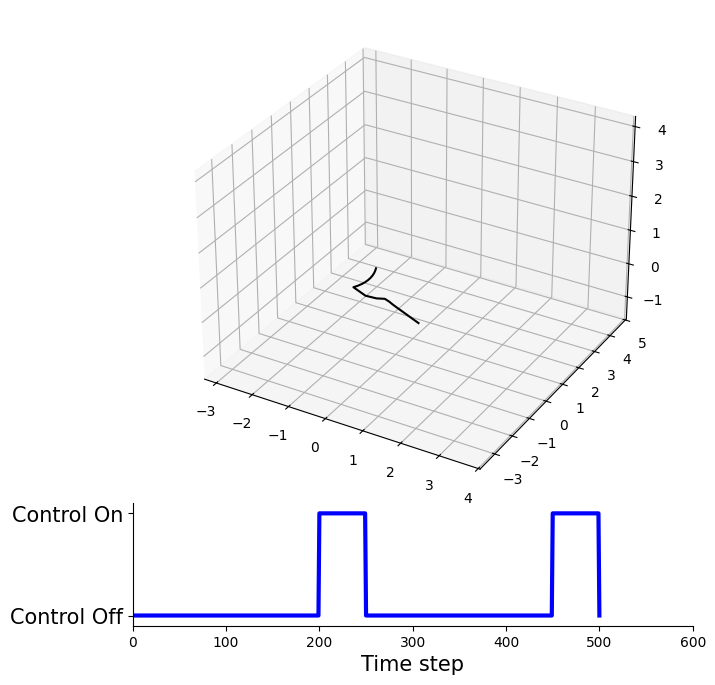

In [ ]:
fig = plt.figure(figsize=(8, 8))

# Create GridSpec with height ratios
gs = gridspec.GridSpec(2, 1, figure=fig, height_ratios=[4, 1])

# Add subplots using GridSpec
ax1 = fig.add_subplot(gs[0], projection='3d')
ax2 = fig.add_subplot(gs[1])
# add space at the left of the second plot
plt.subplots_adjust(left=0.2, hspace=0.01)

slowing_factor = 6  # Factor by which to slow down the video when control is on
slowing_status = 1  # Counter to track slowing status
summ_slowings = 0
def update(num, data):
    global slowing_status
    global summ_slowings
    num = num - summ_slowings
    if num<3 or not CONTROL_STATUS[num-3] == 1 or slowing_status >= slowing_factor:
        ax1.clear()
        slowing_status = 1
    else:
        # slow video down when control is on
        slowing_status += 1
        summ_slowings += 1
        return ax1, ax2
        
    ax1.plot(data[np.max([num-60, 0]):num, 0], data[np.max([num-60, 0]):num, 1], data[np.max([num-60, 0]):num, 2], color='black')
    ax1.set_xlim(data[ :, 0].min()-1, data[ :, 0].max()+1)
    ax1.set_ylim(data[ :, 1].min()-1, data[ :, 1].max()+1)
    ax1.set_zlim(data[ :, 2].min()-1, data[ :, 2].max()+1)
    # angle of view
    
    ax2.clear()
    ax2.plot(CONTROL_STATUS[:num], color='blue', linewidth=3)
    ax2.set_ylim(-0.1, 1.1)
    ax2.set_xlim(0, 600)
    ax2.set_xlabel('Time step', fontsize=15)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    ax2.set_yticks([0, 1], labels=['Control Off', 'Control On'], fontsize=15)
    return ax1, ax2

ani = animation.FuncAnimation(fig, update, frames=1000, fargs=(observed_trajectory_all[53].detach().cpu().numpy(), ), interval=50, blit=False)
# save
ani.save('lorenz_trajectory.mp4', writer='ffmpeg', fps=30)
plt.show()